# Proyecto Centinela — Fase 3: industrialización y despliegue
**Profundización I: Deep Learning · Maestría en Ciencia de Datos · USTA** · Fase 3

Cuaderno ejecutado en Google Colab con GPU **Tesla T4**. Cubre las seis tareas de la guía: entorno de GPU (3.2), pipelines en PyTorch y TensorFlow (3.3), aumento de datos y Mixup (3.4), entrenamiento con precisión mixta (3.5, 3.5b y 3.6), optimización para el borde por cuantización INT8 (3.8) y exportación a `.pth`, `.onnx` y `.keras` (3.7, 3.8 y 3.9).

**Alcance y contexto.** El escenario de la guía (roya, AGROSAVIA, RoCoLe) se sustituye por el caso del proyecto aprobado por el profesor el 18-nov-2026: recortes Sentinel-1 de 224 × 224 × 3 (VV, VH y VH − VV en dB) de la cuenca del río Cauca en La Virginia, con etiqueta de **3 clases** del cambio de nivel a +24 h (baja < −4 cm, estable ±4 cm, sube > +4 cm). Los datos no provienen de Kaggle.

**Resultado en una frase.** El *pipeline* de despliegue (GPU, precisión mixta, ONNX, INT8, Keras) funciona y se verificó, pero **el modelo de imagen no supera a la referencia de la clase mayoritaria**: no es apto para operar como alerta.

**Nota de auditoría.** En una primera ejecución los PNG se nombraban solo con la fecha del ancla IDEAM y varias escenas se sobrescribían (154 imágenes de entrenamiento en vez de 189). Se detectó al comparar el resumen de la 3.2 con el conteo de la 3.3, se corrigió (un archivo por escena, con verificación) y **todas las celdas de este cuaderno se volvieron a ejecutar con los datos correctos**.

### 3.0 Arranque
Monta el Drive, define las rutas y fija la semilla (42). Lee los recortes ya generados en la Fase 2 (sin depender de sus variables).

In [1]:
# ============================================================
# CELDA 3.0 — ARRANQUE DEL CUADERNO DE LA FASE 3
# Monta el Drive y define las rutas. No depende de las Fases 1 y 2:
# lee los recortes que dejó la celda 2.24a (antes 3.1) del cuaderno de las Fases 1 y 2.
# ============================================================
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from google.colab import drive

drive.mount("/content/drive")

CARPETA_BASE = "/content/drive/MyDrive/Centinela"
CARPETA_FASE_3 = os.path.join(CARPETA_BASE, "Fase_3")
RUTA_RECORTES = os.path.join(CARPETA_FASE_3, "centinela_recortes_sar_224.npz")
assert os.path.exists(RUTA_RECORTES), "No encuentro los recortes (celda 2.24a del cuaderno de las Fases 1 y 2) en tu Drive."

semilla = 42
random.seed(semilla)
np.random.seed(semilla)
torch.manual_seed(semilla)
print("Recortes encontrados:", RUTA_RECORTES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Recortes encontrados: /content/drive/MyDrive/Centinela/Fase_3/centinela_recortes_sar_224.npz


### 3.2 Entorno GPU y carpetas train / val / test por clases (Tarea 1)
`nvidia-smi` y PyTorch documentan el tipo de GPU, la VRAM y la capacidad de cómputo; la cuota restante de Colab no tiene API y se anota a mano. Partición cronológica 70/15/15 (lo más antiguo entrena, lo más reciente prueba), PNG de 8 bits con límites calculados solo con entrenamiento.

In [2]:
# ============================================================
# CELDA 3.2 — ENTORNO GPU Y CARPETAS train / val / test POR CLASES, 3 CLASES (Fase 3, Tarea 1)
# Requiere la 3.1 NUEVA (usa RUTA_RECORTES y CARPETA_FASE_3; el .npz trae y = 0 baja, 1 estable, 2 sube).
# Partición cronológica 70/15/15 (igual que en las Fases 1 y 2): lo más antiguo entrena,
# lo más reciente prueba. Las imágenes se guardan como PNG de 8 bits en el disco local de
# Colab (rápido); se pueden regenerar en cualquier momento desde el .npz de la 3.1.
# ============================================================
import subprocess, shutil
from PIL import Image

# --- 1) GPU: tipo, VRAM y cuota ------------------------------------------
print("GPU (PyTorch):", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "NO HAY GPU: en Colab ve a Entorno de ejecución > Cambiar tipo > T4 GPU")
if torch.cuda.is_available():
    libre, total = torch.cuda.mem_get_info()
    print(f"VRAM total: {total / 1e9:.1f} GB | libre ahora: {libre / 1e9:.1f} GB")
    print("Capacidad de cómputo:", torch.cuda.get_device_capability(0))
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi no disponible (el runtime no tiene GPU).")
print("Cuota de cómputo restante: se consulta en Colab > Ver recursos / Administrar sesiones "
      "(no hay API pública); anótala a mano en el informe.")

# --- 2) Datos y partición cronológica ------------------------------------
datos = np.load(RUTA_RECORTES, allow_pickle=True)
X, y = datos["X"].astype("float32"), datos["y"]
fechas = pd.to_datetime(datos["fecha"])
etq_escenas = [str(e) for e in datos["etiqueta"]]
assert len(set(etq_escenas)) == len(etq_escenas), "Hay etiquetas de escena repetidas"
n = len(X)
i70, i85 = int(n * 0.70), int(n * 0.85)
particiones = {"train": range(0, i70), "val": range(i70, i85), "test": range(i85, n)}

# --- 3) Escala a 8 bits con límites calculados SOLO en entrenamiento -----
idx_ent = np.array(list(particiones["train"]))
limites_canal = [(np.percentile(X[idx_ent, c], 1), np.percentile(X[idx_ent, c], 99))
                 for c in range(3)]

def a_png(imagen):
    canales = []
    for c, (lo, hi) in enumerate(limites_canal):
        canales.append(np.clip((imagen[c] - lo) / (hi - lo), 0, 1))
    return Image.fromarray((np.stack(canales, axis=-1) * 255).astype("uint8"))

# --- 4) Carpetas train/val/test/{baja, estable, sube} -------------------
RAIZ_IMAGENES = "/content/centinela_imagenes"
if os.path.exists(RAIZ_IMAGENES):
    shutil.rmtree(RAIZ_IMAGENES)
nombre_clase = {0: "baja", 1: "estable", 2: "sube"}
for parte, indices in particiones.items():
    for clase in nombre_clase.values():
        os.makedirs(os.path.join(RAIZ_IMAGENES, parte, clase), exist_ok=True)
    for i in indices:
        nombre = f"{etq_escenas[i]}.png"          # una imagen por ESCENA (la fecha del ancla IDEAM puede repetirse)
        a_png(X[i]).save(os.path.join(RAIZ_IMAGENES, parte, nombre_clase[int(y[i])], nombre))

for parte in particiones:
    n_archivos = sum(len(os.listdir(os.path.join(RAIZ_IMAGENES, parte, c))) for c in nombre_clase.values())
    assert n_archivos == len(particiones[parte]), f"{parte}: {n_archivos} archivos en disco, se esperaban {len(particiones[parte])}"
print("Verificación: el número de PNG en disco coincide con el de escenas de cada conjunto.")

resumen = pd.DataFrame({
    parte: {nombre_clase[c]: int((y[list(ind)] == c).sum()) for c in (0, 1, 2)}
    for parte, ind in particiones.items()
}).T
resumen["total"] = resumen.sum(axis=1)
resumen["% clase mayoritaria"] = (100 * resumen[list(nombre_clase.values())].max(axis=1) / resumen["total"]).round(1)
print("\nImágenes por conjunto y clase:")
print(resumen.to_string())
print("\nRango de fechas:", {p: (f"{fechas[list(i)[0]]:%Y-%m-%d}", f"{fechas[list(i)[-1]]:%Y-%m-%d}")
                           for p, i in particiones.items()})
print("Límites dB por canal (de entrenamiento):",
      [(round(float(a), 1), round(float(b), 1)) for a, b in limites_canal])

GPU (PyTorch): Tesla T4
VRAM total: 15.6 GB | libre ahora: 13.5 GB
Capacidad de cómputo: (7, 5)
Sun Nov 22 18:39:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             34W /   70W |    2005MiB /  15360MiB |      0%      Default |
|                                         | 

**Lectura.** GPU Tesla T4 (15.6 GB, capacidad 7.5). **189 imágenes de entrenamiento** (92 baja, 51 estable, 46 sube), **41 de validación** (21, 13, 7) y **41 de prueba** (18, 12, 11); la verificación confirma que hay un PNG en disco por escena. La clase mayoritaria vale 51.2 % en validación y 43.9 % en prueba: esa es la referencia que el modelo debe superar. Con solo 7 y 11 imágenes de "sube" las métricas por clase son muy inestables.

### 3.3 Pipeline de datos en PyTorch y TensorFlow (Tarea 2)
El mismo pipeline en `DataLoader` y `tf.data`, con y sin optimizaciones (workers, `pin_memory`, prefetch, cache, shuffle). Se mide el tiempo de una época completa de lectura simulando el trabajo de la GPU con una pausa fija por lote.

Clases PyTorch: {'baja': 0, 'estable': 1, 'sube': 2} | imágenes: 189
TensorFlow 2.21.0 | GPUs vistas por TF: 1

Tiempo de una época de lectura (segundos):
                                                                           época 1 (s)  época 2 (s)  época 3 (s)
framework  configuración                                                                                        
PyTorch    optimizado (workers=2, pin_memory, prefetch_factor=2)                  0.61         0.50         0.50
           sin optimizar (num_workers=0)                                          1.35         1.11         0.89
TensorFlow optimizado (map paralelo + cache + shuffle + batch + prefetch)         1.27         0.32         0.33
           sin optimizar (map secuencial, sin cache ni prefetch)                  0.64         0.63         0.45

Nota: la época 1 de tf.data con .cache() incluye el llenado de la caché; las siguientes ya leen desde memoria.


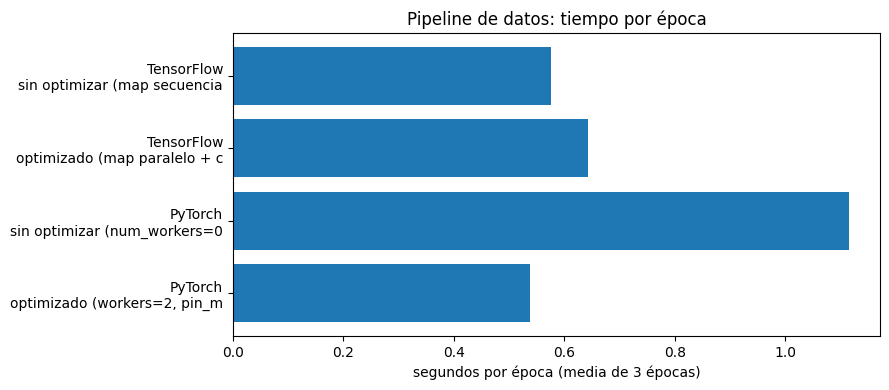

In [3]:
# ============================================================
# CELDA 3.3 (3 clases: baja / estable / sube) — PIPELINE DE DATOS EN PYTORCH Y TENSORFLOW (Fase 3, Tarea 2)
# Mismo pipeline en los dos frameworks. Se mide el tiempo de UNA ÉPOCA completa de lectura
# con y sin optimizaciones. Para que el solapamiento CPU-GPU sea visible se simula el trabajo
# de la GPU con una pausa fija por lote (PAUSA_GPU); el entrenamiento real viene en la 3.5.
# Requiere la 3.2 (usa RAIZ_IMAGENES y CARPETA_FASE_3).
# ============================================================
import glob, time
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

TAM_LOTE = 32
EPOCAS_MEDIDAS = 3
PAUSA_GPU = 0.05        # segundos de "cómputo" simulado por lote
MEDIA_IMAGENET = [0.485, 0.456, 0.406]
DESV_IMAGENET = [0.229, 0.224, 0.225]
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tiempos = []

# ---------------- PyTorch: ImageFolder + DataLoader -----------------------
transformacion = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEDIA_IMAGENET, DESV_IMAGENET),
])
ds_torch = datasets.ImageFolder(os.path.join(RAIZ_IMAGENES, "train"), transform=transformacion)
N_CLASES = len(ds_torch.classes)
print("Clases PyTorch:", ds_torch.class_to_idx, "| imágenes:", len(ds_torch))

def medir_torch(nombre, **opciones):
    g = torch.Generator(); g.manual_seed(semilla)
    cargador = DataLoader(ds_torch, batch_size=TAM_LOTE, shuffle=True, generator=g, **opciones)
    for epoca in range(1, EPOCAS_MEDIDAS + 1):
        t0 = time.perf_counter()
        for xb, yb in cargador:
            xb = xb.to(dispositivo, non_blocking=True)
            yb = yb.to(dispositivo, non_blocking=True)
            time.sleep(PAUSA_GPU)
        if dispositivo.type == "cuda":
            torch.cuda.synchronize()
        tiempos.append({"framework": "PyTorch", "configuración": nombre,
                        "época": epoca, "segundos": time.perf_counter() - t0})

medir_torch("sin optimizar (num_workers=0)", num_workers=0, pin_memory=False)
medir_torch("optimizado (workers=2, pin_memory, prefetch_factor=2)",
            num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

# ---------------- TensorFlow: tf.data ------------------------------------
import tensorflow as tf
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)   # no acapara toda la VRAM
print("TensorFlow", tf.__version__, "| GPUs vistas por TF:", len(tf.config.list_physical_devices("GPU")))

rutas_tf = sorted(glob.glob(os.path.join(RAIZ_IMAGENES, "train", "*", "*.png")))
etiquetas_tf = [ds_torch.class_to_idx[os.path.basename(os.path.dirname(r))] for r in rutas_tf]
n_tf = len(rutas_tf)
media_tf = tf.constant(MEDIA_IMAGENET, dtype=tf.float32)
desv_tf = tf.constant(DESV_IMAGENET, dtype=tf.float32)

def cargar_tf(ruta, etiqueta):
    img = tf.io.decode_png(tf.io.read_file(ruta), channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    return (img - media_tf) / desv_tf, etiqueta

base_tf = tf.data.Dataset.from_tensor_slices((rutas_tf, etiquetas_tf))

def medir_tf(nombre, dataset):
    for epoca in range(1, EPOCAS_MEDIDAS + 1):
        t0 = time.perf_counter()
        for xb, yb in dataset:
            time.sleep(PAUSA_GPU)
        tiempos.append({"framework": "TensorFlow", "configuración": nombre,
                        "época": epoca, "segundos": time.perf_counter() - t0})

sin_opt = (base_tf.shuffle(n_tf, seed=semilla).map(cargar_tf).batch(TAM_LOTE))
con_opt = (base_tf.map(cargar_tf, num_parallel_calls=tf.data.AUTOTUNE)
           .cache().shuffle(n_tf, seed=semilla).batch(TAM_LOTE).prefetch(tf.data.AUTOTUNE))
medir_tf("sin optimizar (map secuencial, sin cache ni prefetch)", sin_opt)
medir_tf("optimizado (map paralelo + cache + shuffle + batch + prefetch)", con_opt)

# ---------------- Resultados ---------------------------------------------
df_t = pd.DataFrame(tiempos)
resumen_t = df_t.pivot_table(index=["framework", "configuración"], columns="época",
                             values="segundos").round(2)
resumen_t.columns = [f"época {c} (s)" for c in resumen_t.columns]
print("\nTiempo de una época de lectura (segundos):")
print(resumen_t.to_string())
print("\nNota: la época 1 de tf.data con .cache() incluye el llenado de la caché; "
      "las siguientes ya leen desde memoria.")
df_t.to_csv(os.path.join(CARPETA_FASE_3, "centinela_pipeline_tiempos.csv"),
            index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(9, 4))
medias = df_t.groupby(["framework", "configuración"])["segundos"].mean()
ax.barh([f"{f}\n{c[:28]}" for f, c in medias.index], medias.values)
ax.set_xlabel("segundos por época (media de %d épocas)" % EPOCAS_MEDIDAS)
ax.set_title("Pipeline de datos: tiempo por época")
plt.tight_layout()
plt.show()

**Lectura.** En PyTorch, las épocas 2 y 3 tardan unos **0.50 s optimizadas** frente a 0.89 a 1.11 s sin optimizar. En TensorFlow, **0.32 a 0.33 s** con `map` paralelo + `cache` + `prefetch` frente a 0.45 a 0.63 s sin optimizar; la época 1 con `cache` (1.27 s) incluye el llenado de la caché. Con solo 189 imágenes en disco local las diferencias son de fracciones de segundo; el beneficio crece con conjuntos grandes o discos lentos.

### 3.4 Aumento de datos y Mixup (Tarea 3)
ResNet-18 preentrenada, 10 épocas, 3 semillas: A) sin aumento, B) cuatro transformaciones (recorte, rotación ±10°, volteo horizontal, *jitter* suave de brillo y contraste), C) B + Mixup (α = 0.2). Las transformaciones contraproducentes en SAR (volteo vertical, rotaciones grandes, cambios de tono y de brillo fuertes, que alteran los dB) están justificadas en el código de la celda. Se muestra una grilla 3 × 3 de originales y aumentadas.

Validación: 41 imágenes, por clase {'baja': 21, 'estable': 13, 'sube': 7}.
Referencia: responder siempre 'baja' daría exactitud 0.512 y F1 macro 0.226.
A) sin aumento | semilla 0: exactitud 0.463 | F1 macro 0.427
A) sin aumento | semilla 1: exactitud 0.488 | F1 macro 0.332
A) sin aumento | semilla 2: exactitud 0.512 | F1 macro 0.363
B) 4 transformaciones | semilla 0: exactitud 0.195 | F1 macro 0.130
B) 4 transformaciones | semilla 1: exactitud 0.561 | F1 macro 0.531
B) 4 transformaciones | semilla 2: exactitud 0.512 | F1 macro 0.499
C) 4 transformaciones + Mixup | semilla 0: exactitud 0.390 | F1 macro 0.302
C) 4 transformaciones + Mixup | semilla 1: exactitud 0.585 | F1 macro 0.527
C) 4 transformaciones + Mixup | semilla 2: exactitud 0.341 | F1 macro 0.305

Validación tras 10 épocas (media de 3 semillas; 41 imágenes de validación):
                               exactitud_media  exactitud_desv  F1_media  F1_desv
configuración                                                             

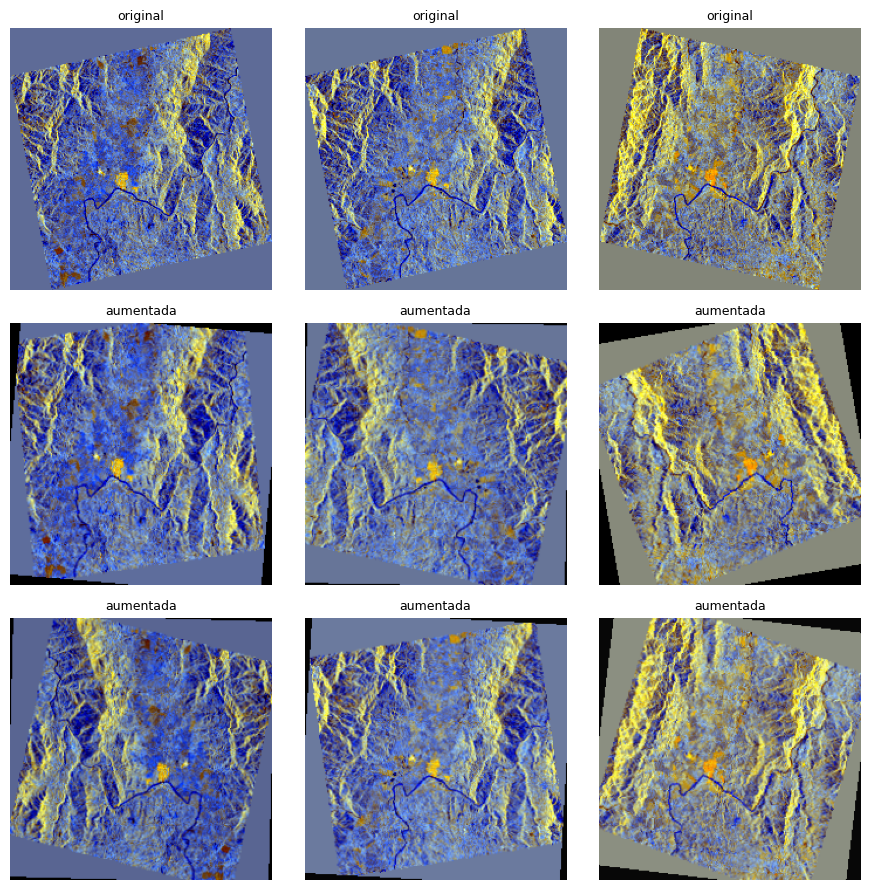

In [4]:
# ============================================================
# CELDA 3.4 — AUMENTO DE DATOS Y MIXUP (Fase 3, Tarea 3)
# Compara, tras 10 épocas (3 clases: baja/estable/sube), la exactitud y el F1 macro de validación de una ResNet-18 preentrenada:
#   A) sin aumento | B) con 4 transformaciones | C) con las 4 transformaciones + Mixup
# Se repite con 3 semillas y se reporta media y desviación. La PRUEBA no se toca aquí.
# Se evalúa en la época 10 (no se elige la mejor época), para no inflar el resultado.
# Requiere la 3.3 (usa RAIZ_IMAGENES, TAM_LOTE, MEDIA_IMAGENET, DESV_IMAGENET, dispositivo, semilla).
#
# Justificación de las transformaciones (imágenes SAR de 3 canales VV / VH / VH-VV):
#  - RandomResizedCrop (escala 0.8-1.0): simula pequeños cambios de encuadre; conserva la textura.
#  - RandomRotation (±10°): la escena ya está rotada en la malla; rotaciones pequeñas son realistas.
#  - RandomHorizontalFlip: aceptable con prudencia; refleja también sombras y "layover" del radar
#    (el satélite siempre ilumina desde el mismo lado), por eso se usa solo con p = 0.5.
#  - ColorJitter: SOLO suave (brillo/contraste 0.1). Es el equivalente a la roya: alterar mucho el brillo
#    cambia los dB y borraría justo la señal de agua/humedad; un jitter fuerte sería contraproducente.
#  - Contraproducentes aquí: volteo vertical, rotaciones grandes y cambios de tono o saturación.
# ============================================================
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

EPOCAS_AUM = 10
SEMILLAS_AUM = [0, 1, 2]
ALFA_MIXUP = 0.2

normaliza = transforms.Normalize(MEDIA_IMAGENET, DESV_IMAGENET)
t_base = transforms.Compose([transforms.ToTensor(), normaliza])
aumentos_pil = [
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
]
t_aum = transforms.Compose(aumentos_pil + [transforms.ToTensor(), normaliza])

ds_sin = datasets.ImageFolder(os.path.join(RAIZ_IMAGENES, "train"), transform=t_base)
ds_con = datasets.ImageFolder(os.path.join(RAIZ_IMAGENES, "train"), transform=t_aum)
ds_val = datasets.ImageFolder(os.path.join(RAIZ_IMAGENES, "val"), transform=t_base)

conteo = np.bincount(ds_sin.targets)
pesos_clase = torch.tensor(len(ds_sin) / (N_CLASES * conteo), dtype=torch.float32)   # compensa el desbalance
conteo_val = np.bincount(ds_val.targets, minlength=N_CLASES)
base_mayoritaria = float(conteo_val.max() / len(ds_val))
clase_mayoritaria = ds_val.classes[int(conteo_val.argmax())]
f1_base = f1_score(ds_val.targets, [int(conteo_val.argmax())] * len(ds_val), average="macro", zero_division=0)
print(f"Validación: {len(ds_val)} imágenes, por clase {dict(zip(ds_val.classes, conteo_val.tolist()))}.")
print(f"Referencia: responder siempre '{clase_mayoritaria}' daría exactitud {base_mayoritaria:.3f} y F1 macro {f1_base:.3f}.")

def mezclar(xb, yb, alfa):
    lam = float(np.random.beta(alfa, alfa))
    perm = torch.randperm(xb.size(0), device=xb.device)
    return lam * xb + (1 - lam) * xb[perm], yb, yb[perm], lam

def entrenar_y_evaluar(dataset_ent, usar_mixup, semilla_r):
    torch.manual_seed(semilla_r); np.random.seed(semilla_r); random.seed(semilla_r)
    g = torch.Generator(); g.manual_seed(semilla_r)
    dl_ent = DataLoader(dataset_ent, batch_size=TAM_LOTE, shuffle=True, generator=g,
                        num_workers=2, pin_memory=True)
    dl_val = DataLoader(ds_val, batch_size=TAM_LOTE, shuffle=False)
    modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    modelo.fc = torch.nn.Linear(modelo.fc.in_features, N_CLASES)
    modelo.to(dispositivo)
    criterio = torch.nn.CrossEntropyLoss(weight=pesos_clase.to(dispositivo))
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=3e-4, weight_decay=1e-4)
    for _ in range(EPOCAS_AUM):
        modelo.train()
        for xb, yb in dl_ent:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            optimizador.zero_grad()
            if usar_mixup:
                xm, ya, yb2, lam = mezclar(xb, yb, ALFA_MIXUP)
                salida = modelo(xm)
                perdida = lam * criterio(salida, ya) + (1 - lam) * criterio(salida, yb2)
            else:
                perdida = criterio(modelo(xb), yb)
            perdida.backward()
            optimizador.step()
    modelo.eval()
    pred, real = [], []
    with torch.no_grad():
        for xb, yb in dl_val:
            pred.append(modelo(xb.to(dispositivo)).argmax(1).cpu().numpy())
            real.append(yb.numpy())
    pred, real = np.concatenate(pred), np.concatenate(real)
    return accuracy_score(real, pred), f1_score(real, pred, average="macro", zero_division=0)

configuraciones = {
    "A) sin aumento": (ds_sin, False),
    "B) 4 transformaciones": (ds_con, False),
    "C) 4 transformaciones + Mixup": (ds_con, True),
}
filas = []
for nombre, (dataset, mixup) in configuraciones.items():
    for s in SEMILLAS_AUM:
        acc, f1 = entrenar_y_evaluar(dataset, mixup, s)
        filas.append({"configuración": nombre, "semilla": s, "exactitud_val": acc, "F1_macro_val": f1})
        print(f"{nombre} | semilla {s}: exactitud {acc:.3f} | F1 macro {f1:.3f}")

df_aum = pd.DataFrame(filas)
tabla_aum = df_aum.groupby("configuración").agg(
    exactitud_media=("exactitud_val", "mean"), exactitud_desv=("exactitud_val", "std"),
    F1_media=("F1_macro_val", "mean"), F1_desv=("F1_macro_val", "std")).round(3)
print(f"\nValidación tras {EPOCAS_AUM} épocas (media de {len(SEMILLAS_AUM)} semillas; {len(ds_val)} imágenes de validación):")
print(tabla_aum.to_string())
df_aum.to_csv(os.path.join(CARPETA_FASE_3, "centinela_aumento_comparacion.csv"),
              index=False, encoding="utf-8-sig")

# --- Grilla 3x3: originales (fila 1) frente a dos versiones aumentadas (filas 2 y 3) -----------------
torch.manual_seed(semilla); random.seed(semilla)
rutas_muestra = [r for r, _ in ds_sin.samples][::max(len(ds_sin) // 3, 1)][:3]
transforma_pil = transforms.Compose(aumentos_pil)
fig, ejes = plt.subplots(3, 3, figsize=(9, 9))
for col, ruta in enumerate(rutas_muestra):
    original = Image.open(ruta).convert("RGB")
    ejes[0, col].imshow(original); ejes[0, col].set_title("original", fontsize=9)
    for fila in (1, 2):
        ejes[fila, col].imshow(transforma_pil(original)); ejes[fila, col].set_title("aumentada", fontsize=9)
for a in ejes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

**Lectura.** F1 macro medio en validación: A 0.374 (± 0.048), B 0.387 (± 0.223), C 0.378 (± 0.129); exactitud media A 0.488, B 0.423, C 0.439. **No hay mejora demostrable con aumento ni con Mixup**: las medias son similares y la variabilidad entre semillas es mucho mayor (en B, una semilla colapsó a exactitud 0.195). Con 41 imágenes de validación las diferencias son ruido. Se mantiene la configuración A (sin aumento) para las celdas siguientes.

#### Limpieza previa al entrenamiento
Borra checkpoints y modelos de ejecuciones anteriores para que la 3.5 no reanude desde pesos viejos. Solo afecta a `Fase_3/checkpoints` y `Fase_3/modelos`.

In [5]:
import shutil, os
for carpeta in [os.path.join(CARPETA_FASE_3, "checkpoints"), os.path.join(CARPETA_FASE_3, "modelos")]:
    shutil.rmtree(carpeta, ignore_errors=True)
    os.makedirs(carpeta, exist_ok=True)
print("Checkpoints y modelos anteriores borrados.")

Checkpoints y modelos anteriores borrados.


### 3.5 Entrenamiento acelerado en GPU con precisión mixta (Tarea 4)
ResNet-18 preentrenada, 20 épocas, misma semilla en float32 y en float16 con escalado de pérdida (AMP). Se mide tiempo por época y VRAM pico, se guarda un *checkpoint* cada 5 épocas (con reanudación), se grafican las curvas de pérdida y se prueba qué pasa ante un CUDA OOM. La 3.5b aísla el cómputo de la GPU con tensores aleatorios.

         modo  segundos_por_época  VRAM_pico_MB  exactitud_val_final  F1_macro_val_final  AUC_val_final
      float32               0.828      1185.664                0.512               0.387          0.573
float16 (AMP)               0.649       842.566                0.512               0.392          0.569

Aceleración t32/t16 = 1.28x | ahorro de VRAM pico = 28.9 %
Referencia de validación: responder siempre 'baja' da exactitud 0.512, F1 macro 0.226 y AUC = 0.5.


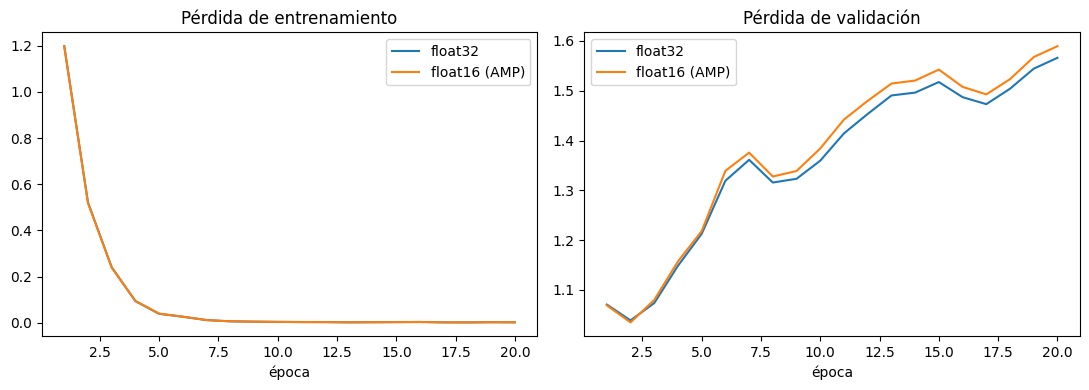


PRUEBA DE MEMORIA: ¿cabe un paso de entrenamiento con este tamaño de lote?
 tamaño_de_lote  float32 float16 (AMP)
             64     cabe          cabe
            128     cabe          cabe
            256     cabe          cabe
            512     cabe          cabe
           1024 CUDA OOM          cabe
Solución aplicada ante un OOM: reducir el tamaño de lote (o activar float16, que reduce la memoria de activaciones); con lotes pequeños se puede acumular gradientes para conservar el lote efectivo.


In [6]:
# ============================================================
# CELDA 3.5 — ENTRENAMIENTO ACELERADO EN GPU (Fase 3, Tarea 4)
# ResNet-18 preentrenada (transfer learning), configuración A (sin aumento, la mejor en validación
# de la 3.4), learning rate 1e-4 (más bajo que en la 3.4 por la inestabilidad observada).
# Se entrena dos veces con la MISMA semilla: float32 y precisión mixta float16 (en la T4: float16
# con escalado de pérdida, GradScaler). Se mide tiempo por época y VRAM, se guarda un checkpoint
# cada 5 épocas (con reanudación) y se prueba qué pasa al quedarse sin memoria (CUDA OOM).
# La PRUEBA no se toca aquí. Requiere la 3.4 (usa ds_sin, ds_val, pesos_clase, TAM_LOTE, etc.).
# ============================================================
import gc, time
from sklearn.metrics import roc_auc_score

EPOCAS_GPU = 20
LR_GPU = 1e-4
CADA_N_CKPT = 5
CARPETA_MODELOS = os.path.join(CARPETA_FASE_3, "modelos")
CARPETA_CKPT = os.path.join(CARPETA_FASE_3, "checkpoints")
os.makedirs(CARPETA_MODELOS, exist_ok=True)
os.makedirs(CARPETA_CKPT, exist_ok=True)

def nuevo_modelo():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = torch.nn.Linear(m.fc.in_features, N_CLASES)
    return m.to(dispositivo)

def auc_ovr(reales, probs):
    try:
        return roc_auc_score(reales, probs, multi_class="ovr", average="macro", labels=list(range(N_CLASES)))
    except ValueError:      # falta alguna clase en validación
        return float("nan")

def evaluar(modelo, dl, criterio, usar_amp):
    modelo.eval()
    perdida_total, probs, reales = 0.0, [], []
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usar_amp):
                salida = modelo(xb)
                perdida_total += criterio(salida, yb).item() * len(yb)
            probs.append(torch.softmax(salida.float(), 1).cpu().numpy())
            reales.append(yb.cpu().numpy())
    probs, reales = np.concatenate(probs), np.concatenate(reales)
    pred = probs.argmax(1)
    return {"perdida_val": perdida_total / len(reales),
            "exactitud_val": accuracy_score(reales, pred),
            "F1_macro_val": f1_score(reales, pred, average="macro", zero_division=0),
            "AUC_val": auc_ovr(reales, probs)}

def entrenar_gpu(nombre, usar_amp, semilla_r=42):
    torch.manual_seed(semilla_r); np.random.seed(semilla_r); random.seed(semilla_r)
    g = torch.Generator(); g.manual_seed(semilla_r)
    dl_ent = DataLoader(ds_sin, batch_size=TAM_LOTE, shuffle=True, generator=g, num_workers=2,
                        pin_memory=True, persistent_workers=True, prefetch_factor=2)
    dl_val = DataLoader(ds_val, batch_size=TAM_LOTE, shuffle=False)
    modelo = nuevo_modelo()
    criterio = torch.nn.CrossEntropyLoss(weight=pesos_clase.to(dispositivo))
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=LR_GPU, weight_decay=1e-4)
    escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)
    ruta_ckpt = os.path.join(CARPETA_CKPT, f"resnet18_{nombre}.pt")
    historial, epoca_ini = [], 1
    if os.path.exists(ruta_ckpt):                       # reanudación tras una caída de sesión
        ck = torch.load(ruta_ckpt, map_location=dispositivo, weights_only=False)
        modelo.load_state_dict(ck["modelo"]); optimizador.load_state_dict(ck["optimizador"])
        escalador.load_state_dict(ck["escalador"]); historial = ck["historial"]
        epoca_ini = ck["epoca"] + 1
        print(f"[{nombre}] reanudando desde la época {epoca_ini}")
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    vram_inicial = torch.cuda.memory_allocated() / 1e6
    for epoca in range(epoca_ini, EPOCAS_GPU + 1):
        modelo.train()
        t0 = time.perf_counter(); suma, n = 0.0, 0
        for xb, yb in dl_ent:
            xb, yb = xb.to(dispositivo, non_blocking=True), yb.to(dispositivo, non_blocking=True)
            optimizador.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usar_amp):
                perdida = criterio(modelo(xb), yb)
            escalador.scale(perdida).backward()
            escalador.step(optimizador); escalador.update()
            suma += perdida.item() * len(yb); n += len(yb)
        torch.cuda.synchronize()
        segundos = time.perf_counter() - t0
        fila = {"modo": nombre, "época": epoca, "segundos": segundos,
                "perdida_ent": suma / n, **evaluar(modelo, dl_val, criterio, usar_amp)}
        historial.append(fila)
        if epoca % CADA_N_CKPT == 0:
            torch.save({"epoca": epoca, "modelo": modelo.state_dict(),
                        "optimizador": optimizador.state_dict(),
                        "escalador": escalador.state_dict(), "historial": historial}, ruta_ckpt)
    vram_pico = torch.cuda.max_memory_allocated() / 1e6
    torch.save(modelo.state_dict(), os.path.join(CARPETA_MODELOS, f"resnet18_{nombre}_epoca{EPOCAS_GPU}.pth"))
    del modelo, optimizador, dl_ent, dl_val
    gc.collect(); torch.cuda.empty_cache()
    return pd.DataFrame(historial), vram_inicial, vram_pico

h32, v32_ini, v32_pico = entrenar_gpu("fp32", usar_amp=False)
h16, v16_ini, v16_pico = entrenar_gpu("fp16_amp", usar_amp=True)
hist_gpu = pd.concat([h32, h16], ignore_index=True)
hist_gpu.to_csv(os.path.join(CARPETA_FASE_3, "centinela_entrenamiento_gpu_historial.csv"),
                index=False, encoding="utf-8-sig")

# --- Tiempos y VRAM (se ignora la época 1: calentamiento de cuDNN) ---------
t32 = h32.loc[h32["época"] > 1, "segundos"].mean()
t16 = h16.loc[h16["época"] > 1, "segundos"].mean()
resumen_gpu = pd.DataFrame({
    "modo": ["float32", "float16 (AMP)"],
    "segundos_por_época": [t32, t16],
    "VRAM_pico_MB": [v32_pico, v16_pico],
    "exactitud_val_final": [h32["exactitud_val"].iloc[-1], h16["exactitud_val"].iloc[-1]],
    "F1_macro_val_final": [h32["F1_macro_val"].iloc[-1], h16["F1_macro_val"].iloc[-1]],
    "AUC_val_final": [h32["AUC_val"].iloc[-1], h16["AUC_val"].iloc[-1]],
}).round(3)
print(resumen_gpu.to_string(index=False))
print(f"\nAceleración t32/t16 = {t32 / t16:.2f}x | ahorro de VRAM pico = "
      f"{100 * (1 - v16_pico / v32_pico):.1f} %")
print(f"Referencia de validación: responder siempre '{clase_mayoritaria}' da exactitud {base_mayoritaria:.3f}, F1 macro {f1_base:.3f} y AUC = 0.5.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for modo, h in [("float32", h32), ("float16 (AMP)", h16)]:
    ejes[0].plot(h["época"], h["perdida_ent"], label=modo)
    ejes[1].plot(h["época"], h["perdida_val"], label=modo)
ejes[0].set_title("Pérdida de entrenamiento"); ejes[1].set_title("Pérdida de validación")
for a in ejes:
    a.set_xlabel("época"); a.legend()
plt.tight_layout(); plt.show()

# --- Prueba de memoria insuficiente (CUDA OOM) -----------------------------
def cabe(tamano, usar_amp):
    try:
        m = nuevo_modelo(); m.train()
        opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
        x = torch.randn(tamano, 3, 224, 224, device=dispositivo)
        y = torch.randint(0, N_CLASES, (tamano,), device=dispositivo)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usar_amp):
            perdida = torch.nn.functional.cross_entropy(m(x), y)
        perdida.backward(); opt.step()
        ok = True
    except torch.cuda.OutOfMemoryError:
        ok = False
    gc.collect(); torch.cuda.empty_cache()
    return ok

print("\nPRUEBA DE MEMORIA: ¿cabe un paso de entrenamiento con este tamaño de lote?")
filas_oom = []
for tam in [64, 128, 256, 512, 1024]:
    filas_oom.append({"tamaño_de_lote": tam, "float32": "cabe" if cabe(tam, False) else "CUDA OOM",
                      "float16 (AMP)": "cabe" if cabe(tam, True) else "CUDA OOM"})
print(pd.DataFrame(filas_oom).to_string(index=False))
print("Solución aplicada ante un OOM: reducir el tamaño de lote (o activar float16, que reduce la memoria "
      "de activaciones); con lotes pequeños se puede acumular gradientes para conservar el lote efectivo.")

In [7]:
# ============================================================
# CELDA 3.5b — BENCHMARK DE CÓMPUTO PURO: float32 frente a float16 (AMP)
# Aísla la GPU: usa tensores aleatorios ya en la GPU (sin leer imágenes), para medir lo que la
# precisión mixta acelera de verdad. En la 3.5 cada época es de solo 5 lotes y el tiempo lo
# domina la lectura de datos, por eso allí no se vio aceleración. Requiere la 3.5.
# ============================================================
def cronometrar(usar_amp, lote, iteraciones=30, calentamiento=5):
    modelo = nuevo_modelo(); modelo.train()
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-4)
    escalador = torch.amp.GradScaler("cuda", enabled=usar_amp)
    x = torch.randn(lote, 3, 224, 224, device=dispositivo)
    y = torch.randint(0, N_CLASES, (lote,), device=dispositivo)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    for i in range(calentamiento + iteraciones):
        if i == calentamiento:
            torch.cuda.synchronize(); t0 = time.perf_counter()
        optimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=usar_amp):
            perdida = torch.nn.functional.cross_entropy(modelo(x), y)
        escalador.scale(perdida).backward()
        escalador.step(optimizador); escalador.update()
    torch.cuda.synchronize()
    seg_por_lote = (time.perf_counter() - t0) / iteraciones
    pico = torch.cuda.max_memory_allocated() / 1e6
    del modelo, optimizador, x, y, perdida
    gc.collect(); torch.cuda.empty_cache()
    return seg_por_lote, pico

filas_b = []
for lote in [32, 128]:
    s32, p32 = cronometrar(False, lote)
    s16, p16 = cronometrar(True, lote)
    filas_b.append({"lote": lote,
                    "ms_por_lote_fp32": round(1000 * s32, 1), "ms_por_lote_fp16": round(1000 * s16, 1),
                    "imágenes_por_s_fp32": round(lote / s32), "imágenes_por_s_fp16": round(lote / s16),
                    "aceleración_t32/t16": round(s32 / s16, 2),
                    "VRAM_fp32_MB": round(p32), "VRAM_fp16_MB": round(p16)})
tabla_bench = pd.DataFrame(filas_b)
print(tabla_bench.to_string(index=False))
tabla_bench.to_csv(os.path.join(CARPETA_FASE_3, "centinela_benchmark_gpu.csv"),
                   index=False, encoding="utf-8-sig")

 lote  ms_por_lote_fp32  ms_por_lote_fp16  imágenes_por_s_fp32  imágenes_por_s_fp16  aceleración_t32/t16  VRAM_fp32_MB  VRAM_fp16_MB
   32             113.2              57.5                  283                  556                 1.97          1185           842
  128             419.5             200.3                  305                  639                 2.09          3373          2062


**Lectura.** float32: 0.83 s por época y 1 186 MB de VRAM pico; float16 (AMP): 0.65 s y 843 MB, es decir **1.28× más rápido y 28.9 % menos VRAM**. Aislando el cómputo (3.5b) la aceleración es de **1.97× (lote 32) y 2.09× (lote 128)**, porque en el entrenamiento real el tiempo lo domina la lectura de datos. La precisión mixta no degrada el resultado (exactitud 0.512 en ambos; F1 macro 0.387 y 0.392). Prueba de memoria: con lote 1024 float32 da **CUDA OOM** y float16 cabe; la solución es reducir el lote, usar float16 o acumular gradientes.

### 3.6 Reentrenamiento con parada anticipada: el modelo que se comprime y se exporta
Se conserva la época de menor pérdida de validación y se detiene tras 3 épocas sin mejora. La prueba no se toca aquí.

Entrenamiento detenido en la época 5; mejor época (menor pérdida de validación): 2
Validación en la mejor época: pérdida 1.035 | exactitud 0.317 | F1 macro 0.183 | AUC 0.614
Referencia de validación: responder siempre 'baja' da exactitud 0.512, F1 macro 0.226 y AUC = 0.5.
Modelo guardado en: /content/drive/MyDrive/Centinela/Fase_3/modelos/resnet18_centinela_final.pth


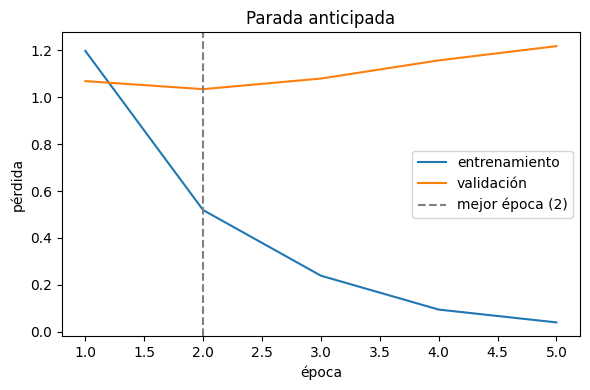

In [8]:
# ============================================================
# CELDA 3.6 — REENTRENAMIENTO CON PARADA ANTICIPADA: EL MODELO QUE SE COMPRIME Y SE EXPORTA
# Regla fijada de antemano: se guarda el modelo de la época con MENOR pérdida de validación y se
# detiene el entrenamiento tras 3 épocas sin mejora. Todo lo demás igual a la 3.5 (configuración A,
# lr 1e-4, float16 con escalado de pérdida, semilla 42). La PRUEBA no se toca aquí: se mira una
# sola vez, en la tabla antes/después de la Tarea 5. Requiere la 3.5 (nuevo_modelo, evaluar, etc.).
# ============================================================
import copy, json

PACIENCIA = 3
MAX_EPOCAS = 20
SEMILLA_FINAL = 42

torch.manual_seed(SEMILLA_FINAL); np.random.seed(SEMILLA_FINAL); random.seed(SEMILLA_FINAL)
g = torch.Generator(); g.manual_seed(SEMILLA_FINAL)
dl_ent = DataLoader(ds_sin, batch_size=TAM_LOTE, shuffle=True, generator=g, num_workers=2,
                    pin_memory=True, persistent_workers=True, prefetch_factor=2)
dl_val = DataLoader(ds_val, batch_size=TAM_LOTE, shuffle=False)
modelo_final = nuevo_modelo()
criterio = torch.nn.CrossEntropyLoss(weight=pesos_clase.to(dispositivo))
optimizador = torch.optim.AdamW(modelo_final.parameters(), lr=LR_GPU, weight_decay=1e-4)
escalador = torch.amp.GradScaler("cuda", enabled=True)

mejor_perdida, mejor_estado, mejor_epoca, sin_mejora = float("inf"), None, 0, 0
historial_final = []
for epoca in range(1, MAX_EPOCAS + 1):
    modelo_final.train()
    suma, n = 0.0, 0
    for xb, yb in dl_ent:
        xb, yb = xb.to(dispositivo, non_blocking=True), yb.to(dispositivo, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            perdida = criterio(modelo_final(xb), yb)
        escalador.scale(perdida).backward()
        escalador.step(optimizador); escalador.update()
        suma += perdida.item() * len(yb); n += len(yb)
    m = evaluar(modelo_final, dl_val, criterio, True)
    historial_final.append({"época": epoca, "perdida_ent": suma / n, **m})
    if m["perdida_val"] < mejor_perdida - 1e-4:
        mejor_perdida, mejor_epoca, sin_mejora = m["perdida_val"], epoca, 0
        mejor_estado = copy.deepcopy(modelo_final.state_dict())
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            break

modelo_final.load_state_dict(mejor_estado)
modelo_final.eval()
del dl_ent; gc.collect()
hist_final = pd.DataFrame(historial_final)
hist_final.to_csv(os.path.join(CARPETA_FASE_3, "centinela_modelo_final_historial.csv"),
                  index=False, encoding="utf-8-sig")

ruta_final = os.path.join(CARPETA_MODELOS, "resnet18_centinela_final.pth")
torch.save(modelo_final.state_dict(), ruta_final)
info = {
    "arquitectura": "resnet18 (torchvision) con fc de 3 salidas (baja / estable / sube)", "mejor_epoca": int(mejor_epoca),
    "epocas_entrenadas": int(len(hist_final)), "clases": ds_val.class_to_idx,
    "normalizacion_imagenet": {"media": MEDIA_IMAGENET, "desv": DESV_IMAGENET},
    "limites_db_por_canal_png": [[float(a), float(b)] for a, b in limites_canal],
    "tam_entrada": [3, 224, 224], "semilla": SEMILLA_FINAL,
}
with open(os.path.join(CARPETA_MODELOS, "resnet18_centinela_final_info.json"), "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

mejor = hist_final.loc[hist_final["época"] == mejor_epoca].iloc[0]
print(f"Entrenamiento detenido en la época {len(hist_final)}; mejor época (menor pérdida de validación): {mejor_epoca}")
print(f"Validación en la mejor época: pérdida {mejor['perdida_val']:.3f} | exactitud {mejor['exactitud_val']:.3f} | "
      f"F1 macro {mejor['F1_macro_val']:.3f} | AUC {mejor['AUC_val']:.3f}")
print(f"Referencia de validación: responder siempre '{clase_mayoritaria}' da exactitud {base_mayoritaria:.3f}, F1 macro {f1_base:.3f} y AUC = 0.5.")
print("Modelo guardado en:", ruta_final)

plt.figure(figsize=(6, 4))
plt.plot(hist_final["época"], hist_final["perdida_ent"], label="entrenamiento")
plt.plot(hist_final["época"], hist_final["perdida_val"], label="validación")
plt.axvline(mejor_epoca, color="gray", linestyle="--", label=f"mejor época ({mejor_epoca})")
plt.xlabel("época"); plt.ylabel("pérdida"); plt.legend(); plt.title("Parada anticipada")
plt.tight_layout(); plt.show()

**Lectura.** El entrenamiento se detuvo en la época 5; la mejor fue la 2 (pérdida de validación 1.035, exactitud 0.317, F1 macro 0.183, AUC 0.614). El modelo sobreajusta muy pronto y en validación **queda por debajo de la referencia** de la clase mayoritaria (exactitud 0.512, F1 macro 0.226).

### 3.7 Exportar a ONNX y verificar consistencia (Tarea 6)
Exportación en float32 y comparación con PyTorch para lotes distintos del de ejemplo (`np.allclose`, atol = 1e-4).

In [9]:
# ============================================================
# CELDA 3.7 — EXPORTAR A ONNX Y VERIFICAR CONSISTENCIA (Fase 3, Tarea 6)
# Exporta el modelo final (3.6) a ONNX en float32 y comprueba que produce las mismas predicciones que
# PyTorch para lotes DISTINTOS del de ejemplo (np.allclose con atol = 1e-4). Es el "pasaporte portable":
# de este .onnx salen la versión INT8 (3.8) y la ruta hacia LiteRT para la tablet.
# Requiere la 3.6 (usa ruta_final, nuevo_modelo, ds_val, CARPETA_MODELOS).
# ============================================================
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxscript", "onnxruntime"], check=True)
import onnx
import onnxruntime as ort

RUTA_ONNX = os.path.join(CARPETA_MODELOS, "resnet18_centinela_fp32.onnx")

modelo_cpu = nuevo_modelo()
modelo_cpu.load_state_dict(torch.load(ruta_final, map_location=dispositivo))
modelo_cpu = modelo_cpu.to("cpu").eval()

ejemplo = torch.randn(2, 3, 224, 224)     # lote de ejemplo = 2 (evita la especialización del lote = 1)
exportador = None
try:
    torch.onnx.export(
        modelo_cpu, (ejemplo,), RUTA_ONNX, input_names=["imagen"], output_names=["logits"],
        dynamo=True, external_data=False,
        dynamic_shapes={"x": {0: torch.export.Dim("lote")}},
    )
    exportador = "torch.export (dynamo=True, el predeterminado en PyTorch >= 2.9)"
except Exception as error:
    print("Exportación con dynamo=True falló:", repr(error)[:300])
    print("Plan B: exportador heredado (dynamo=False).")
    torch.onnx.export(
        modelo_cpu, (ejemplo,), RUTA_ONNX, input_names=["imagen"], output_names=["logits"],
        dynamic_axes={"imagen": {0: "lote"}, "logits": {0: "lote"}}, opset_version=17, dynamo=False,
    )
    exportador = "exportador heredado (dynamo=False, plan B)"

print("Exportado con:", exportador)
onnx.checker.check_model(onnx.load(RUTA_ONNX))
print("onnx.checker: el modelo es válido.")
print(f"Tamaño del .onnx: {os.path.getsize(RUTA_ONNX) / 1e6:.1f} MB | "
      f"tamaño del .pth: {os.path.getsize(ruta_final) / 1e6:.1f} MB")

# --- Verificación con lotes distintos del de ejemplo (imágenes reales de validación) -------
sesion = ort.InferenceSession(RUTA_ONNX, providers=["CPUExecutionProvider"])
entrada = sesion.get_inputs()[0].name
filas_v = []
for lote in [1, 4, 8, 16]:
    x = torch.stack([ds_val[i][0] for i in range(lote)])
    with torch.no_grad():
        referencia = modelo_cpu(x).numpy()
    salida = sesion.run(None, {entrada: x.numpy()})[0]
    filas_v.append({"lote": lote, "diferencia_máxima": float(np.abs(referencia - salida).max()),
                    "np.allclose(atol=1e-4)": bool(np.allclose(referencia, salida, atol=1e-4)),
                    "misma_clase_predicha": bool((referencia.argmax(1) == salida.argmax(1)).all())})
tabla_v = pd.DataFrame(filas_v)
print("\nConsistencia PyTorch (.pth) frente a ONNX:")
print(tabla_v.to_string(index=False))
tabla_v.to_csv(os.path.join(CARPETA_FASE_3, "centinela_verificacion_onnx.csv"),
               index=False, encoding="utf-8-sig")

[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exportado con: torch.export (dynamo=True, el predeterminado en PyTorch >= 2.9)
onnx.checker: el modelo es válido.
Tamaño del .onnx: 44.8 MB | tamaño del .pth: 44.8 MB

Consistencia PyTorch (.pth) frente a ONNX:
 lote  diferencia_máxima  np.allclose(atol=1e-4)  misma_clase_predicha
    1           0.000001                    True                  True
    4           0.000001                    True                  True
    8           0.000001                    True                  True
   16           0.000002                    True       

**Lectura.** `onnx.checker` valida el modelo. La diferencia máxima entre PyTorch y ONNX es de **1 a 2 × 10⁻⁶** para lotes de 1, 4, 8 y 16, y la clase predicha coincide en todos los casos.

### 3.8 Compresión para el borde: cuantización INT8 post-entrenamiento (Tarea 5)
Cuantización estática (QDQ, por canal) del `.onnx` con 50 imágenes de entrenamiento como calibración. Tabla antes / después con tamaño, latencia en CPU (1 hilo, lote = 1, **CPU de Colab, no una tablet**) y métricas en **prueba (se lee una sola vez)**, con matriz de confusión 3 × 3.

In [10]:
# ============================================================
# CELDA 3.8 — COMPRESIÓN PARA EL BORDE: CUANTIZACIÓN INT8 POST-ENTRENAMIENTO (Fase 3, Tarea 5)
# Cuantiza el .onnx float32 a INT8 (cuantización estática, formato QDQ) calibrando con 50 imágenes de
# ENTRENAMIENTO, y compara tres versiones: PyTorch float32, ONNX float32 y ONNX INT8.
# Métricas: tamaño (MB), latencia en CPU (ms/imagen, 1 hilo, lote = 1) y exactitud / F1 / AUC en PRUEBA.
# La prueba se evalúa UNA sola vez, aquí. La latencia se mide en la CPU de Colab, no en la tablet.
# Requiere la 3.7 (usa RUTA_ONNX, modelo_cpu, ruta_final, t_base, RAIZ_IMAGENES, ds_sin, entrada, ort).
# ============================================================
from onnxruntime.quantization import (quantize_static, CalibrationDataReader,
                                      QuantFormat, QuantType)
from sklearn.metrics import confusion_matrix

RUTA_ONNX_INT8 = os.path.join(CARPETA_MODELOS, "resnet18_centinela_int8.onnx")

class LectorCalibracion(CalibrationDataReader):
    def __init__(self, dataset, n=50):
        pasos = max(len(dataset) // n, 1)
        self.muestras = iter([{"imagen": dataset[i][0].unsqueeze(0).numpy()}
                              for i in range(0, len(dataset), pasos)][:n])
    def get_next(self):
        return next(self.muestras, None)

cuantizado = None
try:
    quantize_static(RUTA_ONNX, RUTA_ONNX_INT8, LectorCalibracion(ds_sin),
                    quant_format=QuantFormat.QDQ, per_channel=True,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
    cuantizado = "estática INT8 (QDQ, por canal, calibrada con 50 imágenes de entrenamiento)"
except Exception as error:
    print("Cuantización estática falló:", repr(error)[:400])
    from onnxruntime.quantization import quantize_dynamic
    quantize_dynamic(RUTA_ONNX, RUTA_ONNX_INT8, weight_type=QuantType.QInt8)
    cuantizado = "dinámica INT8 de pesos (plan B)"
print("Cuantización:", cuantizado)

# --- Prueba: se lee UNA vez ---------------------------------------------------
ds_test = datasets.ImageFolder(os.path.join(RAIZ_IMAGENES, "test"), transform=t_base)
x_test = torch.stack([ds_test[i][0] for i in range(len(ds_test))])
y_test = np.array(ds_test.targets)

def softmax_np(z):
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

def opciones_un_hilo():
    o = ort.SessionOptions(); o.intra_op_num_threads = 1
    return o

sesion_fp32 = ort.InferenceSession(RUTA_ONNX, opciones_un_hilo(), providers=["CPUExecutionProvider"])
sesion_int8 = ort.InferenceSession(RUTA_ONNX_INT8, opciones_un_hilo(), providers=["CPUExecutionProvider"])
torch.set_num_threads(1)

def logits_torch(x):
    with torch.no_grad():
        return modelo_cpu(x).numpy()
def logits_onnx(sesion, x):
    return sesion.run(None, {"imagen": x.numpy()})[0]

def latencia_ms(funcion, repeticiones=100, calentamiento=10):
    una = x_test[:1]
    for _ in range(calentamiento):
        funcion(una)
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter(); funcion(una); tiempos.append(1000 * (time.perf_counter() - t0))
    return float(np.median(tiempos)), float(np.percentile(tiempos, 95))

variantes = {
    "PyTorch float32 (.pth)": (lambda x: logits_torch(x), ruta_final),
    "ONNX float32 (.onnx)": (lambda x: logits_onnx(sesion_fp32, x), RUTA_ONNX),
    "ONNX INT8 (.onnx)": (lambda x: logits_onnx(sesion_int8, x), RUTA_ONNX_INT8),
}
referencia_clase = logits_torch(x_test).argmax(1)
filas_e = []
matrices = {}
for nombre, (funcion, ruta) in variantes.items():
    logits = np.concatenate([funcion(x_test[i:i + 11]) for i in range(0, len(x_test), 11)])
    prob = softmax_np(logits)
    pred = logits.argmax(1)
    med, p95 = latencia_ms(funcion)
    cm = confusion_matrix(y_test, pred, labels=list(range(N_CLASES)))
    matrices[nombre] = cm
    filas_e.append({
        "versión": nombre, "tamaño_MB": round(os.path.getsize(ruta) / 1e6, 1),
        "latencia_mediana_ms": round(med, 1), "latencia_p95_ms": round(p95, 1),
        "exactitud_prueba": round(accuracy_score(y_test, pred), 3),
        "F1_macro_prueba": round(f1_score(y_test, pred, average="macro", zero_division=0), 3),
        "AUC_ovr_prueba": round(auc_ovr(y_test, prob), 3),
        "aciertos_sube": f"{cm[2,2]}/{cm[2].sum()}",
        "coincide_con_PyTorch_%": round(100 * float((pred == referencia_clase).mean()), 1),
    })
tabla_edge = pd.DataFrame(filas_e)
print(f"\nTABLA ANTES / DESPUÉS (prueba: {len(y_test)} imágenes; CPU de Colab, 1 hilo, lote = 1)")
print(tabla_edge.to_string(index=False))
cuenta_test = np.bincount(y_test, minlength=N_CLASES)
base_may = float(cuenta_test.max() / len(y_test))
f1_base_test = f1_score(y_test, [int(cuenta_test.argmax())] * len(y_test), average="macro", zero_division=0)
print(f"Prueba por clase: {dict(zip(ds_test.classes, cuenta_test.tolist()))}")
print(f"Referencia en prueba: responder siempre '{ds_test.classes[int(cuenta_test.argmax())]}' da exactitud {base_may:.3f}, F1 macro {f1_base_test:.3f} y AUC = 0.5.")
for nombre, cm in matrices.items():
    print(f"\nMatriz de confusión 3x3 — {nombre} (filas = real, columnas = predicho; orden {ds_test.classes}):")
    print(pd.DataFrame(cm, index=ds_test.classes, columns=ds_test.classes).to_string())
fp32, i8 = tabla_edge.iloc[1], tabla_edge.iloc[2]
print(f"INT8 frente a ONNX float32: tamaño x{fp32['tamaño_MB'] / i8['tamaño_MB']:.1f} menor | "
      f"latencia x{fp32['latencia_mediana_ms'] / i8['latencia_mediana_ms']:.2f} | "
      f"cambio de exactitud {i8['exactitud_prueba'] - fp32['exactitud_prueba']:+.3f} | "
      f"cambio de F1 macro {i8['F1_macro_prueba'] - fp32['F1_macro_prueba']:+.3f}")
tabla_edge.to_csv(os.path.join(CARPETA_FASE_3, "centinela_edge_antes_despues.csv"),
                  index=False, encoding="utf-8-sig")

Cuantización: estática INT8 (QDQ, por canal, calibrada con 50 imágenes de entrenamiento)

TABLA ANTES / DESPUÉS (prueba: 41 imágenes; CPU de Colab, 1 hilo, lote = 1)
               versión  tamaño_MB  latencia_mediana_ms  latencia_p95_ms  exactitud_prueba  F1_macro_prueba  AUC_ovr_prueba aciertos_sube  coincide_con_PyTorch_%
PyTorch float32 (.pth)       44.8                118.5            218.0             0.293            0.197           0.589          0/11                   100.0
  ONNX float32 (.onnx)       44.8                 35.3             59.2             0.293            0.197           0.589          0/11                   100.0
     ONNX INT8 (.onnx)       11.3                 23.8             28.5             0.244            0.131           0.585          0/11                    95.1
Prueba por clase: {'baja': 18, 'estable': 12, 'sube': 11}
Referencia en prueba: responder siempre 'baja' da exactitud 0.439, F1 macro 0.203 y AUC = 0.5.

Matriz de confusión 3x3 — PyTorch fl

**Lectura.** *Despliegue:* INT8 reduce el tamaño de 44.8 a **11.3 MB (4.0× menos)** y la latencia mediana de 35.3 a **23.8 ms (1.48× frente a ONNX float32)**; frente a PyTorch (118.5 ms) es unas 5 veces más rápido. INT8 coincide con la predicción float32 en el 95.1 % de la prueba y la exactitud baja 0.049.
*Modelo:* en prueba la exactitud es **0.293 (float32) frente a 0.439 de la referencia "siempre baja"**, el F1 macro es 0.197 (referencia 0.203) y el AUC 0.589. La matriz de confusión muestra que el modelo predice casi siempre "estable" y **no acierta ninguna de las 11 imágenes "sube"** (0/11), que es justo la clase de interés. **El modelo no es utilizable como sistema de alerta**; lo que se valida aquí es la cadena técnica de industrialización, no la capacidad predictiva. Con 41 imágenes de prueba, un error de 2 imágenes ya mueve la exactitud 5 puntos.

### 3.9 Modelo complementario en Keras (`.keras`) (Tarea 6)
La guía lista también el formato `.keras`. Como el modelo principal está en PyTorch, se entrena un modelo **complementario** en Keras (ResNet-50 preentrenada y congelada + capa de 3 clases) con las mismas imágenes y se guarda como `.keras`; no es una conversión del modelo de PyTorch. La prueba no se usa aquí.

In [11]:
# ============================================================
# CELDA 3.9 — MODELO COMPLEMENTARIO EN KERAS (.keras) — Fase 3, Tarea 6 (formatos de exportación)
# El modelo principal es la ResNet-18 de PyTorch (.pth / .onnx). Como la guía lista también el formato .keras,
# aquí se entrena un modelo COMPLEMENTARIO en Keras (ResNet-50 preentrenada y congelada + capa de 3 clases) con las
# mismas imágenes y se guarda como .keras. NO es una conversión del modelo de PyTorch.
# La PRUEBA no se toca aquí (se mira una sola vez, en la 3.8). Requiere la 3.3 y la 3.5 (usa tf, RAIZ_IMAGENES,
# CARPETA_MODELOS, N_CLASES, pesos_clase, base_mayoritaria, clase_mayoritaria, f1_base).
# ============================================================
import keras
from sklearn.metrics import f1_score as f1_sk

CLASES = ["baja", "estable", "sube"]
EPOCAS_KERAS = 15
keras.utils.set_random_seed(42)

def cargar(parte, barajar):
    return keras.utils.image_dataset_from_directory(
        os.path.join(RAIZ_IMAGENES, parte), labels="inferred", label_mode="int", class_names=CLASES,
        image_size=(224, 224), batch_size=32, shuffle=barajar, seed=42)

ds_k_ent, ds_k_val = cargar("train", True), cargar("val", False)

base_k = keras.applications.ResNet50(weights="imagenet", include_top=False, pooling="avg",
                                      input_shape=(224, 224, 3))
base_k.trainable = False
entrada = keras.Input(shape=(224, 224, 3))
x = keras.applications.resnet50.preprocess_input(entrada)
x = base_k(x, training=False)
x = keras.layers.Dropout(0.3)(x)
salida = keras.layers.Dense(N_CLASES, activation="softmax")(x)
modelo_keras = keras.Model(entrada, salida)
modelo_keras.compile(optimizer=keras.optimizers.Adam(1e-3),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])

pesos_k = {i: float(p) for i, p in enumerate(pesos_clase.numpy())}
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
hist_k = modelo_keras.fit(ds_k_ent, validation_data=ds_k_val, epochs=EPOCAS_KERAS,
                          class_weight=pesos_k, callbacks=[parada], verbose=2)

reales_v = np.concatenate([y.numpy() for _, y in ds_k_val])
probs_v = modelo_keras.predict(ds_k_val, verbose=0)
pred_v = probs_v.argmax(1)
print(f"\nKeras (ResNet-50 congelada), validación: exactitud {(pred_v == reales_v).mean():.3f} | "
      f"F1 macro {f1_sk(reales_v, pred_v, average='macro', zero_division=0):.3f}")
print(f"Referencia de validación: responder siempre '{clase_mayoritaria}' da exactitud {base_mayoritaria:.3f} "
      f"y F1 macro {f1_base:.3f}.")

RUTA_KERAS = os.path.join(CARPETA_MODELOS, "resnet50_keras_centinela.keras")
modelo_keras.save(RUTA_KERAS)
recargado = keras.models.load_model(RUTA_KERAS)
lote_x, _ = next(iter(ds_k_val))
dif = float(np.abs(modelo_keras.predict(lote_x, verbose=0) - recargado.predict(lote_x, verbose=0)).max())
print(f"Guardado en: {RUTA_KERAS} ({os.path.getsize(RUTA_KERAS) / 1e6:.1f} MB)")
print(f"Verificación de recarga: diferencia máxima entre el modelo y su copia recargada = {dif:.2e}")

Found 189 files belonging to 3 classes.
Found 41 files belonging to 3 classes.
Epoch 1/15
6/6 - 52s - 9s/step - accuracy: 0.2857 - loss: 1.5442 - val_accuracy: 0.3902 - val_loss: 1.1929
Epoch 2/15
6/6 - 1s - 131ms/step - accuracy: 0.3704 - loss: 1.4083 - val_accuracy: 0.3171 - val_loss: 1.2756
Epoch 3/15
6/6 - 1s - 148ms/step - accuracy: 0.3439 - loss: 1.3808 - val_accuracy: 0.4634 - val_loss: 1.0610
Epoch 4/15
6/6 - 1s - 120ms/step - accuracy: 0.3492 - loss: 1.3393 - val_accuracy: 0.4390 - val_loss: 1.1199
Epoch 5/15
6/6 - 1s - 127ms/step - accuracy: 0.3651 - loss: 1.2082 - val_accuracy: 0.4390 - val_loss: 1.0684
Epoch 6/15
6/6 - 2s - 273ms/step - accuracy: 0.3810 - loss: 1.3134 - val_accuracy: 0.4878 - val_loss: 1.0521
Epoch 7/15
6/6 - 1s - 170ms/step - accuracy: 0.4550 - loss: 1.1436 - val_accuracy: 0.4878 - val_loss: 1.0455
Epoch 8/15
6/6 - 1s - 162ms/step - accuracy: 0.3492 - loss: 1.2728 - val_accuracy: 0.3902 - val_loss: 1.0795
Epoch 9/15
6/6 - 1s - 153ms/step - accuracy: 0.4603


Keras (ResNet-50 congelada), validación: exactitud 0.561 | F1 macro 0.452
Referencia de validación: responder siempre 'baja' da exactitud 0.512 y F1 macro 0.226.
Guardado en: /content/drive/MyDrive/Centinela/Fase_3/modelos/resnet50_keras_centinela.keras (95.1 MB)
Verificación de recarga: diferencia máxima entre el modelo y su copia recargada = 0.00e+00


**Lectura.** El archivo `resnet50_keras_centinela.keras` (95.1 MB) se guarda y al recargarlo da **exactamente las mismas predicciones** (diferencia 0). En validación obtiene exactitud 0.561 y F1 macro 0.452 (referencia: 0.512 y 0.226): una mejora pequeña que con 41 imágenes no es concluyente. Las advertencias de *retracing* de TensorFlow son inofensivas.

---
## Ruta de despliegue propuesta y justificación (Tarea 6)
* **Rama visual (imágenes SAR) — sin conexión en la tablet.** `.pth` → `.onnx` (verificado) → INT8 (11.3 MB, 23.8 ms por imagen en una CPU de 1 hilo) → conversión a **LiteRT (.tflite)** para la tablet. Se justifica porque en campo puede no haber conectividad, el modelo cabe y es rápido. **La conversión a LiteRT no se ejecutó**; la latencia se midió en la CPU de Colab y debe confirmarse en la tablet real.
* **Rama temporal (LSTM / GRU) — API REST en la nube.** La serie de nivel del IDEAM necesita datos recientes y conectividad; un servicio ligero (por ejemplo FastAPI) cargaría los pesos de la Fase 2 y devolvería la predicción. Si no hay red, la tablet puede mostrar la última predicción guardada o la persistencia como respaldo.
* **Decisión recomendada.** Dados los resultados (modelo de imagen sin ventaja sobre la referencia, 0/11 aciertos en la clase "sube"), **no se recomienda desplegar el modelo de imagen como alerta**. Sí se recomienda conservar el *pipeline* de industrialización, mejorar los datos (más escenas validadas, más ejemplos de "sube") y reevaluar antes de cualquier uso operativo.
* **Riesgos éticos.** Un falso negativo (no avisar de una crecida) puede costar vidas y bienes; un falso positivo erosiona la confianza. Por eso el sistema solo debería apoyar, no reemplazar, el criterio de los técnicos del IDEAM y de la comunidad. Transparencia: se publican todos los resultados, incluidos los negativos, y las limitaciones (41 imágenes de validación y de prueba; 11 de "sube" en prueba).